In [15]:
from datasets.Harmonized_Datasets import harmonize
import pandas as pd 
import numpy as np 
from scipy.stats import fisher_exact
from statsmodels.stats.contingency_tables import mcnemar
import statsmodels.api as sm

In [2]:
def contingency_table_tests(ct):
    # fisher's exact test
    fe_pval = fisher_exact(ct).pvalue

    # mcnemar's test
    mn_pval = mcnemar(ct).pvalue 

    
    print(f"Fisher's exact test for independence: {fe_pval:.5f}")

    # this is wrong. We need to do model correct, t11;14 correct, model incorrect ...
    print(f"Mcnemar's test to compare as diagnostic: {mn_pval:.5f}")
    return fe_pval, mn_pval


In [3]:
mf_ad = harmonize()["Moffitt"]

/usr/lib/python3.14/functools.py:982: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
/usr/lib/python3.14/functools.py:982: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)


Moffitt Annotated data found!
CoMMpass Annotated data found!
DeCampos Annotated data found!
Number of Harmonized Genes: 18672


/usr/lib/python3.14/functools.py:982: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)


In [4]:
best_model_results = pd.read_csv("../../outputs/best_model_cv_predictions.csv").set_index('samples')

In [5]:
moffitt_observations_df = mf_ad.obs.loc[best_model_results.index]
moffitt_observations_df = moffitt_observations_df[moffitt_observations_df['t11_14'].notna()]

In [6]:
moffitt_observations_df[['y_pred', 'y_prob', 'y_true']] = best_model_results[['y_pred', 'y_prob', 'y_true']]

In [7]:
moffitt_observations_df['model_correct'] = (moffitt_observations_df['y_pred'] == moffitt_observations_df['y_true'])

moffitt_observations_df['t11_14_correct'] = (moffitt_observations_df['t11_14'] == moffitt_observations_df['y_true'])

In [8]:
# make contingency tables
mcn_ct = pd.crosstab(moffitt_observations_df['model_correct'], moffitt_observations_df['t11_14_correct'])

ct_true_labels = pd.crosstab(moffitt_observations_df['y_true'], moffitt_observations_df['t11_14'])

ct_pred_labels = pd.crosstab(moffitt_observations_df['y_pred'], moffitt_observations_df['t11_14'])


In [9]:
mcn_ct

t11_14_correct,False,True
model_correct,,
False,9,5
True,11,29


In [10]:
mcnemar(mcn_ct, exact=True).pvalue

np.float64(0.210113525390625)

In [11]:
fisher_exact(ct_true_labels)

SignificanceResult(statistic=np.float64(4.078431372549019), pvalue=np.float64(0.08796878847886003))

In [12]:
fisher_exact(ct_pred_labels)

SignificanceResult(statistic=np.float64(18.666666666666668), pvalue=np.float64(0.001398294411967163))

In [22]:
y = moffitt_observations_df['ABT-199']
model_1 = sm.OLS(y, sm.add_constant(moffitt_observations_df['t11_14'])).fit(cov_type='HC3')
model_2 = sm.OLS(y, sm.add_constant(moffitt_observations_df['y_prob'])).fit(cov_type='HC3')


model_3 = sm.OLS(y, sm.add_constant(np.column_stack([ moffitt_observations_df['t11_14'], moffitt_observations_df['y_prob']]))).fit(cov_type="HC3")

In [35]:
model_1.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                ABT-199   R-squared:                       0.148
Model:                            OLS   Adj. R-squared:                  0.131
Method:                 Least Squares   F-statistic:                     6.532
Date:                Wed, 04 Nov 2026   Prob (F-statistic):             0.0136
Time:                        10:25:51   Log-Likelihood:                -229.68
No. Observations:                  54   AIC:                             463.4
Df Residuals:                      52   BIC:                             467.3
Df Model:                           1                                         
Covariance Type:                  HC3                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         84.4546      2.560     32.995      0.000      79.438      89.471
t11_14       -17.5957      6.885     -2.556      0.011     -31.089      -4.102
==============================================================================
Omnibus:                        5.761   Durbin-Watson:                   1.747
Prob(Omnibus):                  0.056   Jarque-Bera (JB):                5.292
Skew:                          -0.766   Prob(JB):                       0.0709
Kurtosis:                       3.073   Cond. No.                         2.60
==============================================================================

Notes:
[1] Standard Errors are heteroscedasticity robust (HC3)
"""

In [36]:
model_2.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                ABT-199   R-squared:                       0.226
Model:                            OLS   Adj. R-squared:                  0.212
Method:                 Least Squares   F-statistic:                     23.75
Date:                Wed, 04 Nov 2026   Prob (F-statistic):           1.07e-05
Time:                        10:26:48   Log-Likelihood:                -227.06
No. Observations:                  54   AIC:                             458.1
Df Residuals:                      52   BIC:                             462.1
Df Model:                           1                                         
Covariance Type:                  HC3                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         98.2759      3.793     25.908      0.000      90.841     105.711
y_prob       -37.6554      7.726     -4.874      0.000     -52.798     -22.513
==============================================================================
Omnibus:                       13.025   Durbin-Watson:                   1.959
Prob(Omnibus):                  0.001   Jarque-Bera (JB):               14.322
Skew:                          -1.000   Prob(JB):                     0.000776
Kurtosis:                       4.537   Cond. No.                         5.25
==============================================================================

Notes:
[1] Standard Errors are heteroscedasticity robust (HC3)
"""

In [37]:
model_3.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                ABT-199   R-squared:                       0.271
Model:                            OLS   Adj. R-squared:                  0.242
Method:                 Least Squares   F-statistic:                     12.37
Date:                Wed, 04 Nov 2026   Prob (F-statistic):           4.16e-05
Time:                        10:27:06   Log-Likelihood:                -225.47
No. Observations:                  54   AIC:                             456.9
Df Residuals:                      51   BIC:                             462.9
Df Model:                           2                                         
Covariance Type:                  HC3                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         97.0254      4.018     24.147      0.000      89.150     104.901
x1           -10.5135      7.277     -1.445      0.149     -24.776       3.749
x2           -30.3169      8.793     -3.448      0.001     -47.550     -13.084
==============================================================================
Omnibus:                       12.826   Durbin-Watson:                   1.951
Prob(Omnibus):                  0.002   Jarque-Bera (JB):               14.097
Skew:                          -0.983   Prob(JB):                     0.000869
Kurtosis:                       4.550   Cond. No.                         5.90
==============================================================================

Notes:
[1] Standard Errors are heteroscedasticity robust (HC3)
"""

In [ ]:
# wald test to see if x1 or x2 is signfiicantly different from zero
model_3.wald_test('x1 = 0, x2 = 0', use_f=True)

<class 'statsmodels.stats.contrast.ContrastResults'>
<F test: F=12.373864702706374, p=4.160199947989852e-05, df_denom=51, df_num=2>

Text(0.5, 1.0, 'Multivariable Regression Coefficeints for Drug Response (AUC)')

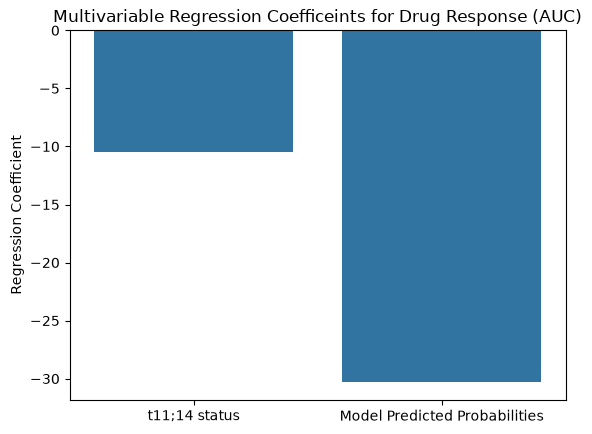

In [47]:
import matplotlib.pyplot as plt
import seaborn as sns
coeffs = {"t11;14 status": model_3.params['x1'], "Model Predicted Probabilities": model_3.params['x2']}

sns.barplot(coeffs)

plt.ylabel('Regression Coefficient')
plt.title("Multivariable Regression Coefficeints for Drug Response (AUC)")
#plt.axhline(y=0, color='k', ls='--')